1. Importa las librerías necesarias para aplicar preprocesamiento de datos,
visualización y creación de un modelo de red neuronal feedforward con Keras y
Tensorflow. Importa la base de datos Customer Churn.csv y realiza el
preprocesamiento de los datos

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_curve, roc_auc_score
from imblearn.over_sampling import SMOTE

import tensorflow as tf
from tensorflow import keras

keras.utils.set_random_seed(42)
plt.style.use('seaborn-v0_8-whitegrid')
print('TensorFlow:', tf.__version__)
print('Keras:', keras.__version__)

I0000 00:00:1792933402.215422   54922 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792933402.833898   54922 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792933407.588635   54922 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow: 2.21.0
Keras: 3.15.1


In [2]:
df = pd.read_csv('Customer Churn.csv')
print('Dimensión original:', df.shape)

df.columns = df.columns.str.replace(r'\s+', ' ', regex=True).str.strip()
print('Columnas:', df.columns.tolist())

print('\nRelación Age vs Age Group:')
print(pd.crosstab(df['Age'], df['Age Group']))
df = df.drop(columns=['Age'])

print('\nValores ausentes:', df.isna().sum().sum())
n_dup = df.duplicated().sum()
print(f'Filas duplicadas: {n_dup} ({n_dup / len(df) * 100:.1f}%)')
df = df.drop_duplicates().reset_index(drop=True)
print('Dimensión tras la limpieza:', df.shape)
df.head()

Dimensión original: (3150, 14)
Columnas: ['Call Failure', 'Complains', 'Subscription Length', 'Charge Amount', 'Seconds of Use', 'Frequency of use', 'Frequency of SMS', 'Distinct Called Numbers', 'Age Group', 'Tariff Plan', 'Status', 'Age', 'Customer Value', 'Churn']

Relación Age vs Age Group:
Age Group    1     2     3    4    5
Age                                 
15         123     0     0    0    0
25           0  1037     0    0    0
30           0     0  1425    0    0
45           0     0     0  395    0
55           0     0     0    0  170

Valores ausentes: 0
Filas duplicadas: 300 (9.5%)
Dimensión tras la limpieza: (2850, 13)


,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,145.805,0


**Observaciones del preprocesamiento:**
- Se normalizan los nombres de columnas, que incluían dobles espacios (`Call  Failure`, `Subscription  Length`, `Charge  Amount`).
- El archivo incluye una columna `Age` no descrita en el enunciado, que es redundante con `Age Group`: cada grupo corresponde a una única edad (tabla cruzada en diagonal). Se elimina para no duplicar información.
- No hay valores ausentes.
- Se eliminan 300 filas duplicadas (9.5%). Si se mantuvieran, al dividir en entrenamiento y test un registro podría quedar en ambos conjuntos, inflando artificialmente las métricas de evaluación.
- Tras la limpieza quedan 2.850 clientes y 12 variables regresoras.

2. Analiza la distribución de “Subscription Length” para cada clase (Churn),
describiendo si hay alguna incidencia de esta variable en la renuncia o no. Realiza
una estandarización de las variables regresoras


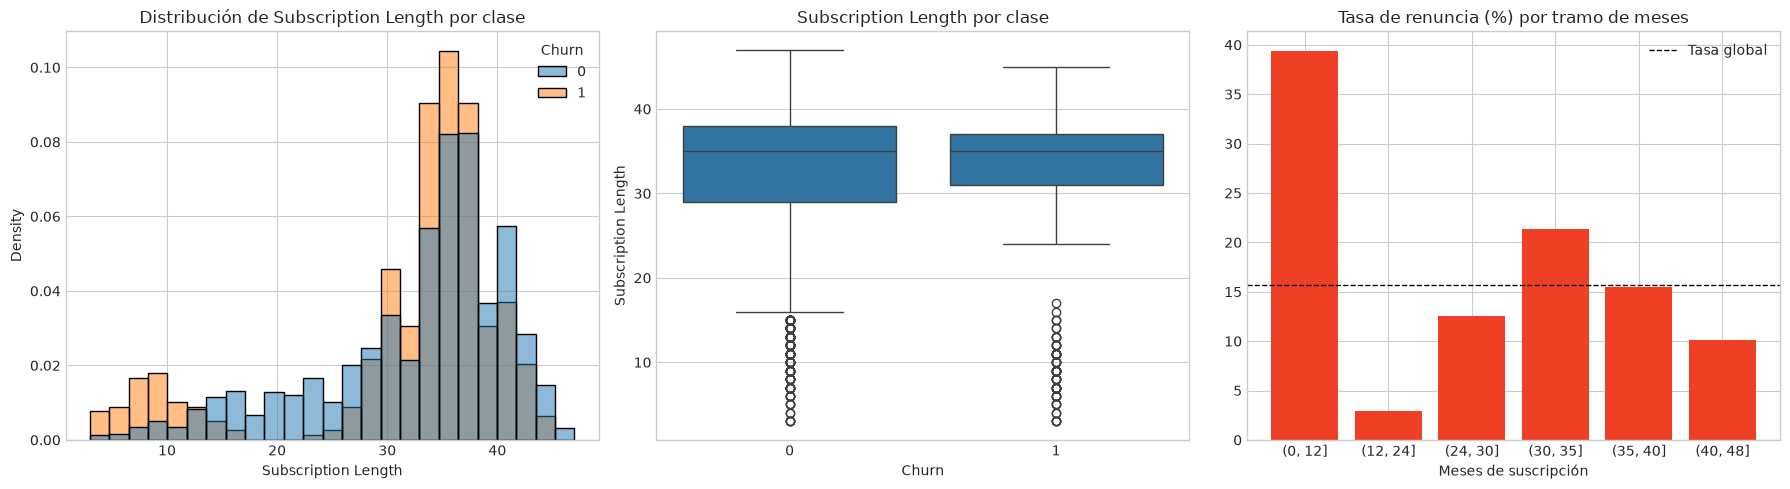

        count  mean  std  min   25%   50%   75%   max
Churn                                                
0      2404.0  32.6  8.5  3.0  29.0  35.0  38.0  47.0
1       446.0  31.7  9.8  3.0  31.0  35.0  37.0  45.0

Tasa de renuncia por tramo:
                     clientes  tasa_churn
Subscription Length                      
(0, 12]                   132       0.394
(12, 24]                  337       0.030
(24, 30]                  336       0.125
(30, 35]                  725       0.214
(35, 40]                  995       0.155
(40, 48]                  325       0.102

Test de Mann-Whitney: p-valor = 0.078


In [3]:
from scipy.stats import mannwhitneyu

var = 'Subscription Length'

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(data=df, x=var, hue='Churn', stat='density',
             common_norm=False, bins=25, ax=axes[0])
axes[0].set_title(f'Distribución de {var} por clase')

sns.boxplot(data=df, x='Churn', y=var, ax=axes[1])
axes[1].set_title(f'{var} por clase')

tramos = pd.cut(df[var], bins=[0, 12, 24, 30, 35, 40, 48])
tasa = df.groupby(tramos, observed=True)['Churn'].agg(['count', 'mean'])
axes[2].bar(tasa.index.astype(str), tasa['mean'] * 100, color='xkcd:tomato')
axes[2].axhline(df['Churn'].mean() * 100, color='black', ls='--', lw=1, label='Tasa global')
axes[2].set_title('Tasa de renuncia (%) por tramo de meses')
axes[2].set_xlabel('Meses de suscripción')
axes[2].legend()

plt.tight_layout()
plt.show()

print(df.groupby('Churn')[var].describe().round(1))
print('\nTasa de renuncia por tramo:')
print(tasa.rename(columns={'count': 'clientes', 'mean': 'tasa_churn'}).round(3))

estadistico, p_valor = mannwhitneyu(df.loc[df['Churn'] == 0, var],
                                    df.loc[df['Churn'] == 1, var])
print(f'\nTest de Mann-Whitney: p-valor = {p_valor:.3f}')

### Análisis de Subscription Length por clase

Comparando las clases completas, la antigüedad del cliente casi no difiere: la mediana es 35 meses en ambas, los promedios son 32.6 (no renuncia) y 31.7 (renuncia), y el test de Mann-Whitney no es significativo (p = 0.078). La correlación lineal con Churn es prácticamente nula (−0.04).

Sin embargo, la forma de las distribuciones es distinta y revela una **incidencia no lineal**: los clientes que renuncian se concentran en dos zonas, los muy nuevos (hasta 12 meses) y entre 30 y 38 meses, y casi no hay renuncias entre los 15 y 27 meses. Por tramos, la tasa de renuncia es de 39.4% en el primer año (2.5 veces la tasa global de 15.6%), cae a 3.0% entre 12 y 24 meses, y vuelve a subir a 21.4% entre 30 y 35 meses.

Por lo tanto, Subscription Length sí incide en la renuncia, pero su efecto depende del tramo y se compensa al mirar promedios globales. Este tipo de relación no puede ser capturada por un modelo lineal, pero sí por modelos no lineales como Random Forest o una red neuronal con capa oculta. Desde el negocio, el primer año de suscripción aparece como el período crítico para acciones de retención.

**Nota metodológica sobre el orden de los pasos:** el enunciado plantea estandarizar y balancear con SMOTE antes de dividir la muestra. Se invierte el orden para evitar fugas de información hacia el conjunto de test: (1) se divide en entrenamiento y test de forma estratificada; (2) el escalador se ajusta solo con el entrenamiento; (3) SMOTE se aplica solo al entrenamiento. Aplicar SMOTE antes de dividir generaría clientes sintéticos en el test interpolados a partir de clientes del entrenamiento, inflando las métricas, y alteraría la proporción real de renuncias con la que debe evaluarse el modelo.

Frecuencia de cada clase:
       clientes  porcentaje
Churn                      
0          2404        84.4
1           446        15.6


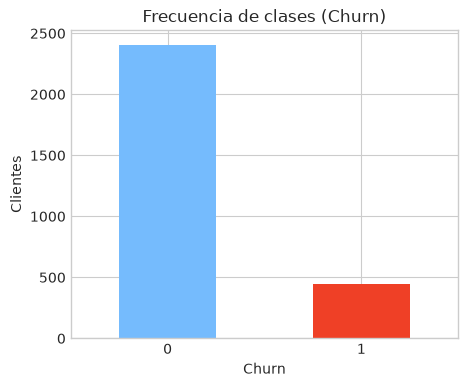

Train: (1909, 12) | Test: (941, 12)
Proporción de renuncias -> train: 0.157 | test: 0.156


In [4]:
X = df.drop(columns=['Churn'])
y = df['Churn']

frecuencia = pd.DataFrame({
    'clientes': y.value_counts(),
    'porcentaje': (y.value_counts(normalize=True) * 100).round(1)
})
print('Frecuencia de cada clase:')
print(frecuencia)

y.value_counts().plot(kind='bar', color=['xkcd:sky blue', 'xkcd:tomato'], figsize=(5, 4))
plt.title('Frecuencia de clases (Churn)')
plt.xticks(rotation=0)
plt.ylabel('Clientes')
plt.show()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42, stratify=y
)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Proporción de renuncias -> train:', round(y_train.mean(), 3),
      '| test:', round(y_test.mean(), 3))

**Observación frecuencia de clases:** la variable objetivo está desbalanceada: 2.404 clientes no renuncian (84.4%) y 446 renuncian (15.6%). Un modelo que prediga siempre "no renuncia" tendría 84.4% de accuracy sin detectar ninguna renuncia, por lo que se evaluará con F1 por clase y AUC. La división estratificada mantiene la proporción en entrenamiento (15.7%) y test (15.6%).

In [5]:
scaler = StandardScaler()
X_train_std = pd.DataFrame(scaler.fit_transform(X_train),
                           columns=X.columns, index=X_train.index)
X_test_std = pd.DataFrame(scaler.transform(X_test),
                          columns=X.columns, index=X_test.index)

print(X_train_std.describe().loc[['mean', 'std']].round(2))

      Call Failure  Complains  Subscription Length  Charge Amount  \
mean          -0.0        0.0                 -0.0           -0.0   
std            1.0        1.0                  1.0            1.0   

      Seconds of Use  Frequency of use  Frequency of SMS  \
mean             0.0              -0.0               0.0   
std              1.0               1.0               1.0   

      Distinct Called Numbers  Age Group  Tariff Plan  Status  Customer Value  
mean                      0.0       -0.0         -0.0     0.0            -0.0  
std                       1.0        1.0          1.0     1.0             1.0  


**Observación estandarización:** las variables regresoras se estandarizan (media 0, desviación 1) ajustando el escalador solo con el conjunto de entrenamiento. Es necesario porque las escalas son muy distintas (Seconds of Use llega a ~17.000, mientras Complains es binaria): en una red neuronal, entradas de magnitudes dispares desbalancean los gradientes y dificultan el entrenamiento, y SMOTE, que se basa en distancias, quedaría dominado por las variables de mayor escala.

In [ ]:
3. Muestra la frecuencia de cada clase y realiza un balanceo de clase usando SMOTE.
Divida el conjunto de datos en entrenamiento y test, considerando para este último
un 33%

In [6]:
print('Clases en train ANTES de SMOTE:')
print(y_train.value_counts())

smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train_std, y_train)

print('\nClases en train DESPUÉS de SMOTE:')
print(y_train_bal.value_counts())
print('\nTrain balanceado:', X_train_bal.shape, '| Test (sin balancear):', X_test_std.shape)

Clases en train ANTES de SMOTE:
Churn
0    1610
1     299
Name: count, dtype: int64

Clases en train DESPUÉS de SMOTE:
Churn
0    1610
1    1610
Name: count, dtype: int64

Train balanceado: (3220, 12) | Test (sin balancear): (941, 12)


**Observación SMOTE:** el conjunto de entrenamiento pasa de 1.610 clientes que no renuncian y 299 que renuncian a 1.610 de cada clase, mediante la generación de 1.311 clientes sintéticos de la clase minoritaria (interpolados entre vecinos cercanos de la misma clase). SMOTE se aplica después de estandarizar, porque se basa en distancias, y solo sobre el entrenamiento: el test conserva 941 clientes reales con la proporción original de renuncias (15.6%).

4. Entrene un modelo RandomForest con hiper parámetros por defecto, usando el
conjunto de entrenamiento anterior y muestra la métrica F1-Score para ambas
clases en el conjunto de test. Captura y muestra las siete características más
importantes detectadas por el modelo RandomForest.

Métricas en test - Random Forest:
              precision    recall  f1-score   support

           0      0.976     0.961     0.968       794
           1      0.805     0.871     0.837       147

    accuracy                          0.947       941
   macro avg      0.890     0.916     0.902       941
weighted avg      0.949     0.947     0.948       941

AUC en test: 0.970


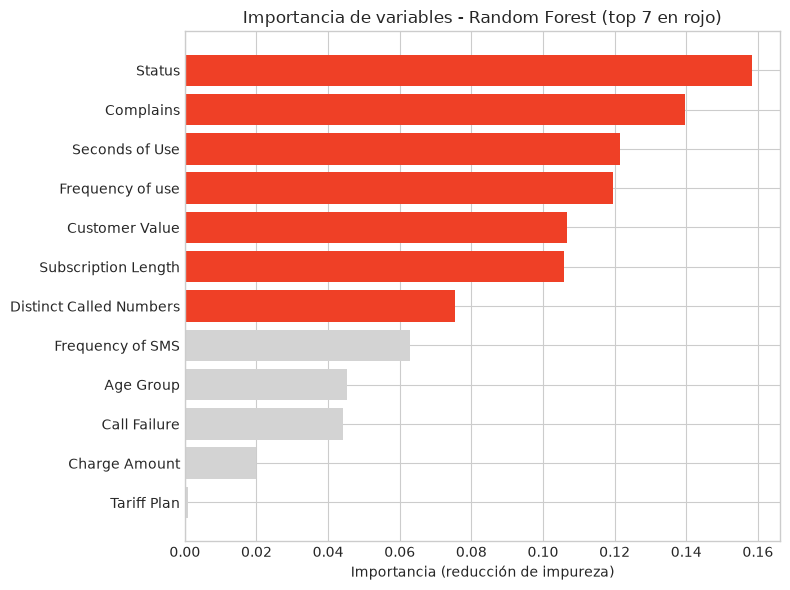


Siete características más importantes:
Status                     0.158
Complains                  0.140
Seconds of Use             0.121
Frequency of use           0.120
Customer Value             0.107
Subscription Length        0.106
Distinct Called Numbers    0.075
dtype: float64


In [7]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train_bal, y_train_bal)

yhat_test_rf = rf.predict(X_test_std)
print('Métricas en test - Random Forest:')
print(classification_report(y_test, yhat_test_rf, digits=3))
auc_rf = roc_auc_score(y_test, rf.predict_proba(X_test_std)[:, 1])
print(f'AUC en test: {auc_rf:.3f}')

importancias_rf = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
top7 = importancias_rf.head(7).index.tolist()

colores = ['xkcd:tomato' if v in top7 else 'lightgray' for v in importancias_rf.index]
plt.figure(figsize=(8, 6))
plt.barh(importancias_rf.index[::-1], importancias_rf.values[::-1], color=colores[::-1])
plt.title('Importancia de variables - Random Forest (top 7 en rojo)')
plt.xlabel('Importancia (reducción de impureza)')
plt.tight_layout()
plt.show()

print('\nSiete características más importantes:')
print(importancias_rf.head(7).round(3))

**Observación Random Forest:** con hiperparámetros por defecto, entrenado sobre el conjunto balanceado, obtiene en test F1 de 0.968 para la clase 0 y 0.837 para la clase 1 (recall 0.871: detecta 128 de 147 renuncias), con AUC de 0.970. El menor F1 de la clase 1 se explica por su menor número de casos en test.

Las siete características más importantes son: Status (0.158), Complains (0.140), Seconds of Use (0.121), Frequency of use (0.120), Customer Value (0.107), Subscription Length (0.106) y Distinct Called Numbers (0.075). Destacan el estado del cliente y las quejas, junto con variables de intensidad de uso. Subscription Length aparece entre las más importantes pese a su correlación lineal casi nula con Churn, lo que confirma su efecto no lineal observado en el paso 2. Tariff Plan prácticamente no aporta (0.001). Estas siete variables se usarán para entrenar la red neuronal.

5. Usando las siete características encontradas anteriormente, filtra el conjunto de
entrenamiento y entrena un modelo de red neuronal feedforward con sólo una capa
oculta. Para esto debes definir una función de activación adecuada, tanto para la
capa oculta como para la capa de salida, la cantidad de neuronas a usar, la tasa de
aprendizaje (learning_rate), y la cantidad de épocas deben ser ajustadas
manualmente. Como optimizador, utiliza el Descenso del Gradiente Estocástico. Los
ajustes manuales de los hiper parámetros deben ser tales que la métrica AUC sea
mayor al 90%. Muestra finalmente ROC y su AUC. (3 Puntos)

Entrenamiento red: (2576, 7) | Validación: (644, 7) | Test: (941, 7)


E0000 00:00:1792935735.822013   54922 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


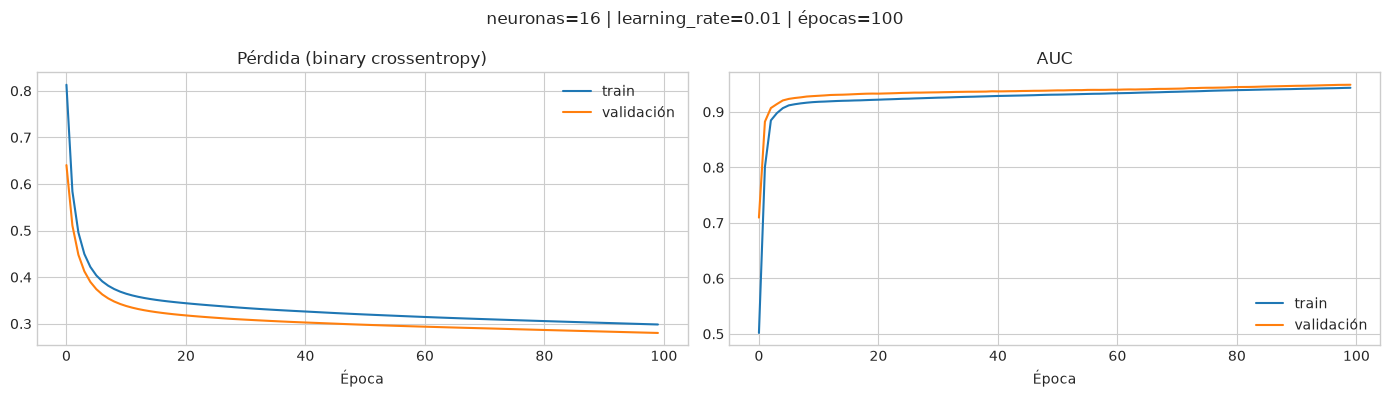

AUC validación: 0.9488 | AUC test: 0.9375


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 147 (592.00 B)

 Trainable params: 145 (580.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

In [8]:
X_train_nn = X_train_bal[top7]
X_test_nn = X_test_std[top7]

X_tr_nn, X_val_nn, y_tr_nn, y_val_nn = train_test_split(
    X_train_nn, y_train_bal, test_size=0.2, random_state=42, stratify=y_train_bal
)
print('Entrenamiento red:', X_tr_nn.shape, '| Validación:', X_val_nn.shape,
      '| Test:', X_test_nn.shape)

registro = []

def entrenar_red(neuronas, learning_rate, epocas, batch_size=32, graficar=True):
    keras.utils.set_random_seed(42)

    modelo = keras.Sequential([
        keras.Input(shape=(len(top7),)),
        keras.layers.Dense(neuronas, activation='relu'),
        keras.layers.Dense(1, activation='sigmoid')
    ])
    modelo.compile(
        optimizer=keras.optimizers.SGD(learning_rate=learning_rate),
        loss='binary_crossentropy',
        metrics=[keras.metrics.AUC(name='auc')]
    )
    historia = modelo.fit(X_tr_nn, y_tr_nn, validation_data=(X_val_nn, y_val_nn),
                          epochs=epocas, batch_size=batch_size, verbose=0)

    proba_test = modelo.predict(X_test_nn, verbose=0).ravel()
    auc_test = roc_auc_score(y_test, proba_test)
    auc_val = historia.history['val_auc'][-1]
    registro.append({'neuronas': neuronas, 'learning_rate': learning_rate,
                     'epocas': epocas, 'auc_val': auc_val, 'auc_test': auc_test})

    if graficar:
        fig, axes = plt.subplots(1, 2, figsize=(14, 4))
        axes[0].plot(historia.history['loss'], label='train')
        axes[0].plot(historia.history['val_loss'], label='validación')
        axes[0].set_title('Pérdida (binary crossentropy)')
        axes[0].set_xlabel('Época')
        axes[0].legend()
        axes[1].plot(historia.history['auc'], label='train')
        axes[1].plot(historia.history['val_auc'], label='validación')
        axes[1].set_title('AUC')
        axes[1].set_xlabel('Época')
        axes[1].legend()
        plt.suptitle(f'neuronas={neuronas} | learning_rate={learning_rate} | épocas={epocas}')
        plt.tight_layout()
        plt.show()

    print(f'AUC validación: {auc_val:.4f} | AUC test: {auc_test:.4f}')
    return modelo, proba_test

modelo_1, proba_1 = entrenar_red(neuronas=16, learning_rate=0.01, epocas=100)
modelo_1.summary()

**Intento 1 (16 neuronas, learning_rate = 0.01, 100 épocas):** AUC de validación 0.949 y de test 0.938, superando la meta de 0.90. La red tiene 145 parámetros entrenables (128 en la capa oculta y 17 en la de salida). Las curvas de train y validación evolucionan juntas, sin señales de sobreajuste, pero la pérdida sigue descendiendo al final del entrenamiento: la red no ha convergido. Esto sugiere que un learning_rate mayor o más épocas podrían mejorar el desempeño.

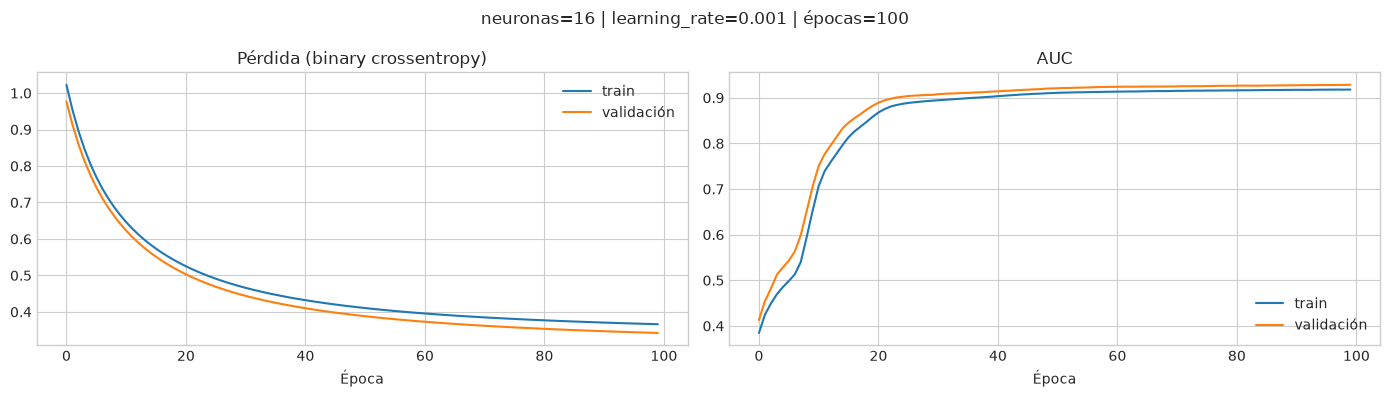

AUC validación: 0.9286 | AUC test: 0.9225


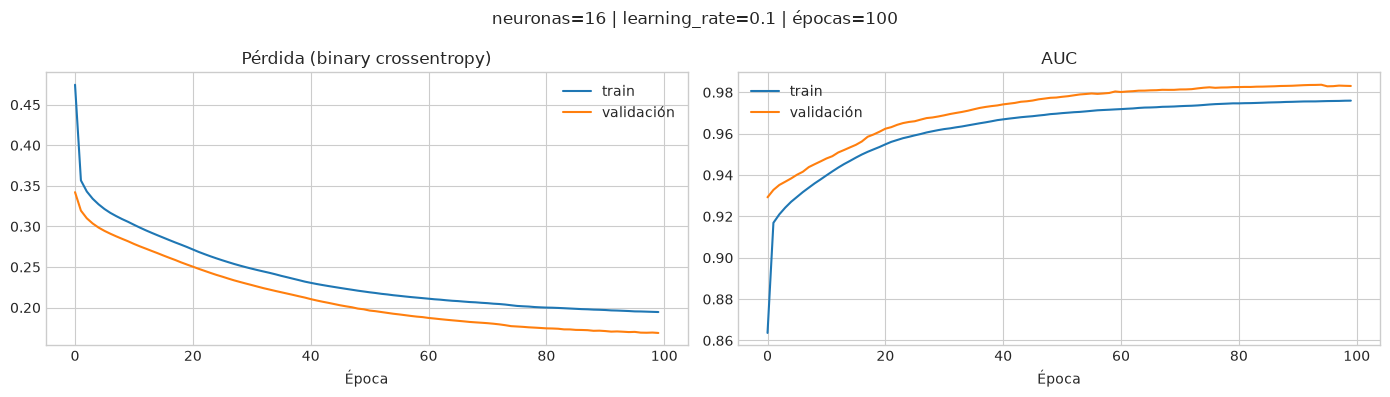

AUC validación: 0.9831 | AUC test: 0.9624


In [9]:
modelo_2, proba_2 = entrenar_red(neuronas=16, learning_rate=0.001, epocas=100)
modelo_3, proba_3 = entrenar_red(neuronas=16, learning_rate=0.1, epocas=100)

**Ajuste del learning_rate (16 neuronas, 100 épocas):** con 0.001 la red aprende muy lentamente (pérdida final ~0.37, AUC test 0.923) y no converge en 100 épocas. Con 0.1 la pérdida desciende rápidamente hasta ~0.19 y el AUC alcanza 0.983 en validación y 0.962 en test, sin oscilaciones ni sobreajuste. Se adopta learning_rate = 0.1. El AUC de validación es mayor que el de test porque la validación proviene del entrenamiento balanceado con SMOTE (clases 50/50 e instancias sintéticas, típicamente más fáciles de clasificar), mientras el test contiene solo clientes reales con la proporción original.

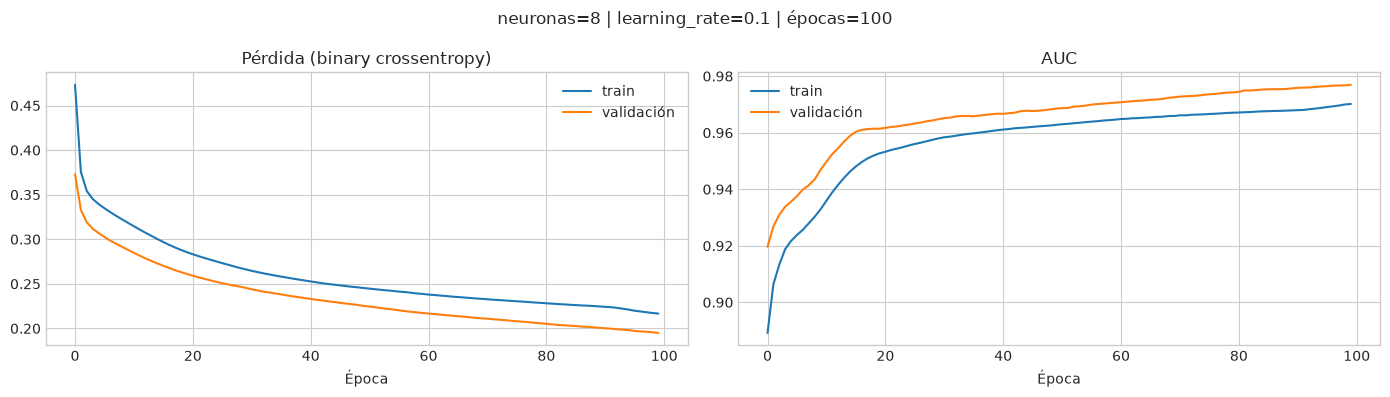

AUC validación: 0.9770 | AUC test: 0.9541


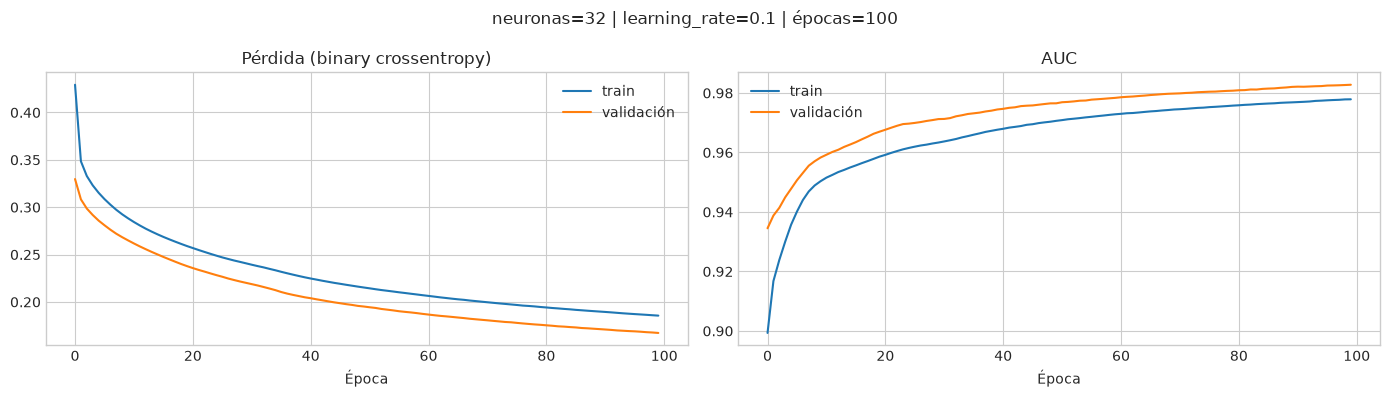

AUC validación: 0.9828 | AUC test: 0.9618


In [10]:
modelo_4, proba_4 = entrenar_red(neuronas=8, learning_rate=0.1, epocas=100)
modelo_5, proba_5 = entrenar_red(neuronas=32, learning_rate=0.1, epocas=100)

**Ajuste del número de neuronas (learning_rate = 0.1, 100 épocas):** con 8 neuronas el AUC desciende levemente (validación 0.977, test 0.954), indicando capacidad algo insuficiente. Con 32 neuronas se obtiene el mismo resultado que con 16 (validación 0.983, test 0.962) duplicando los parámetros (289 vs 145). Se elige 16 neuronas: es la menor arquitectura que alcanza el máximo desempeño, en línea con el teorema de aproximación universal, que garantiza capacidad con "suficientes" neuronas, pero sin indicar cuántas; agregar más solo aumenta la complejidad y el riesgo de sobreajuste.

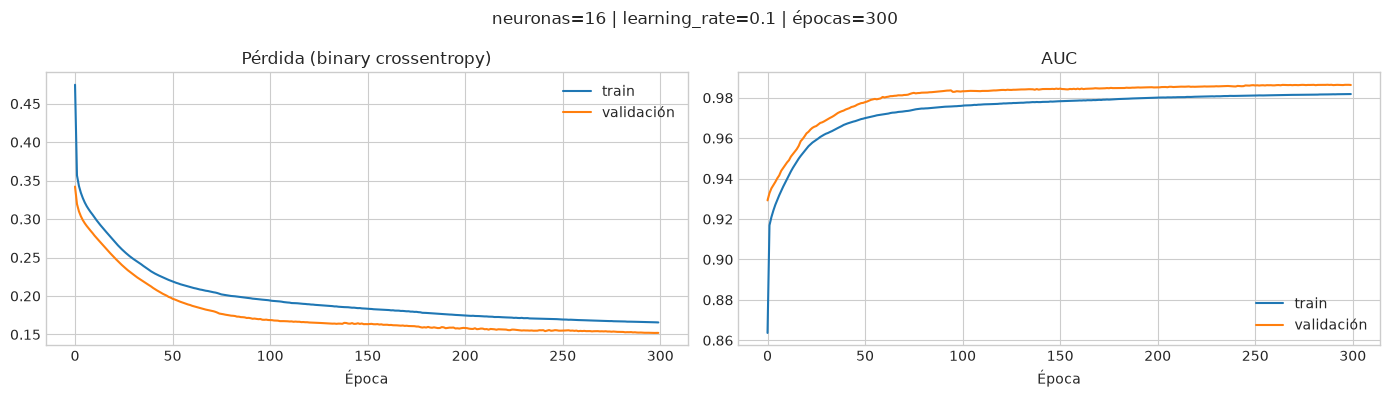

AUC validación: 0.9863 | AUC test: 0.9690


In [11]:
modelo_6, proba_6 = entrenar_red(neuronas=16, learning_rate=0.1, epocas=300)

**Ajuste de épocas (16 neuronas, learning_rate = 0.1):** al aumentar de 100 a 300 épocas, el AUC sube a 0.986 en validación y 0.969 en test. La pérdida de validación desciende rápidamente hasta la época ~75 y luego se estabiliza, con mejoras marginales desde la época ~200 y leves oscilaciones propias del descenso por mini-batches. No hay sobreajuste: la pérdida de validación no aumenta en ningún momento. Se adoptan 300 épocas: más entrenamiento aportaría mejoras despreciables con mayor riesgo de memorización.

**Configuración final:** 7 entradas, 1 capa oculta de 16 neuronas con ReLU, salida de 1 neurona con sigmoide, pérdida binary crossentropy, optimizador SGD con learning_rate = 0.1, batch_size = 32 y 300 épocas.

Registro del ajuste manual de hiperparámetros:
         neuronas  learning_rate  epocas  auc_val  auc_test
intento                                                    
1              16          0.010     100   0.9488    0.9375
2              16          0.001     100   0.9286    0.9225
3              16          0.100     100   0.9831    0.9624
4               8          0.100     100   0.9770    0.9541
5              32          0.100     100   0.9828    0.9618
6              16          0.100     300   0.9863    0.9690


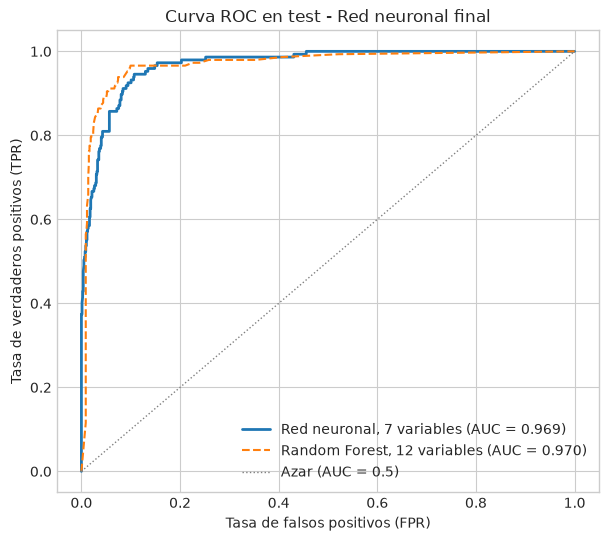

Métricas en test - Red neuronal final (umbral 0.5):
              precision    recall  f1-score   support

           0      0.989     0.875     0.929       794
           1      0.584     0.946     0.722       147

    accuracy                          0.886       941
   macro avg      0.786     0.910     0.825       941
weighted avg      0.925     0.886     0.896       941



In [13]:
tabla_intentos = pd.DataFrame(registro)
tabla_intentos.index = range(1, len(tabla_intentos) + 1)
tabla_intentos.index.name = 'intento'
print('Registro del ajuste manual de hiperparámetros:')
print(tabla_intentos.round(4))

modelo_final, proba_final = modelo_6, proba_6
auc_nn = roc_auc_score(y_test, proba_final)

fpr_nn, tpr_nn, _ = roc_curve(y_test, proba_final)
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf.predict_proba(X_test_std)[:, 1])

plt.figure(figsize=(7, 6))
plt.plot(fpr_nn, tpr_nn, lw=2, label=f'Red neuronal, 7 variables (AUC = {auc_nn:.3f})')
plt.plot(fpr_rf, tpr_rf, lw=1.5, ls='--', label=f'Random Forest, 12 variables (AUC = {auc_rf:.3f})')
plt.plot([0, 1], [0, 1], color='gray', ls=':', lw=1, label='Azar (AUC = 0.5)')
plt.xlabel('Tasa de falsos positivos (FPR)')
plt.ylabel('Tasa de verdaderos positivos (TPR)')
plt.title('Curva ROC en test - Red neuronal final')
plt.legend(loc='lower right')
plt.show()

yhat_final = (proba_final >= 0.5).astype(int)
print('Métricas en test - Red neuronal final (umbral 0.5):')
print(classification_report(y_test, yhat_final, digits=3))

### Curva ROC y métricas del modelo final

**Ajuste manual:** los seis intentos superan el AUC de 0.90 exigido. El hiperparámetro más influyente fue el learning_rate (0.01 → 0.1: +0.025 en AUC test); 16 neuronas resultaron suficientes (8 reducen el desempeño y 32 no lo mejoran), y aumentar de 100 a 300 épocas aportó una mejora final. Configuración elegida: 16 neuronas, learning_rate 0.1, 300 épocas.

**Curva ROC:** la red neuronal alcanza **AUC = 0.969** en test, prácticamente igual al Random Forest (0.970), pese a usar solo 7 de las 12 variables. Las curvas se cruzan: el Random Forest es levemente mejor con tasas de falsos positivos muy bajas (< 0.08) y la red desde FPR ~0.15. La red identifica con total seguridad a un grupo de clientes (TPR ~0.38 con FPR = 0).

**Métricas con umbral 0.5:** en la clase 1, recall de 0.946 (detecta 139 de 147 renuncias) pero precision de 0.584 (F1 = 0.722). La baja precision se explica porque la red se entrenó con datos balanceados por SMOTE (50% de renuncias), por lo que sus probabilidades quedan calibradas para esa proporción y no para la real (15.6%): la probabilidad promedio asignada en test es 0.252. El AUC no se ve afectado porque mide la capacidad de ordenar a los clientes por riesgo, pero el umbral de 0.5 resulta bajo y genera muchas falsas alarmas. En un uso real, el umbral debería ajustarse con datos de validación con la proporción real y según el costo de las acciones de retención: un umbral mayor (por ejemplo, 0.9) equilibra precision y recall (~0.78 cada uno).

## Conclusión final

**Objetivo:** predecir la renuncia de clientes de una compañía de telecomunicaciones iraní mediante una red neuronal feedforward con una capa oculta, usando las variables más importantes identificadas por un Random Forest.

### Preparación y análisis de los datos
- Se eliminó la columna `Age` (redundante con `Age Group`) y 300 filas duplicadas (9.5%), quedando 2.850 clientes y 12 variables regresoras, sin valores ausentes.
- La variable objetivo está desbalanceada: 15.6% de renuncias.
- **Subscription Length** no difiere globalmente entre clases (misma mediana de 35 meses, Mann-Whitney p = 0.078), pero tiene una **incidencia no lineal**: la tasa de renuncia es de 39.4% en el primer año, 3.0% entre 12 y 24 meses y 21.4% entre 30 y 35 meses. El primer año es el período crítico para la retención.
- Para evitar fugas de información, se dividió primero la muestra (67/33, estratificada), y luego se estandarizó y balanceó con SMOTE solo el conjunto de entrenamiento.

### Selección de variables con Random Forest
Con hiperparámetros por defecto, el Random Forest obtuvo en test F1 de 0.968 (clase 0) y 0.837 (clase 1), con AUC de 0.970. Las siete variables más importantes fueron Status, Complains, Seconds of Use, Frequency of use, Customer Value, Subscription Length y Distinct Called Numbers. La inclusión de Subscription Length confirma su efecto no lineal.

### Red neuronal
- **Arquitectura:** 7 entradas → 1 capa oculta de 16 neuronas con ReLU → 1 neurona de salida con sigmoide (145 parámetros entrenables). Pérdida: entropía cruzada binaria. Optimizador: descenso del gradiente estocástico (SGD) con mini-batches de 32.
- **Ajuste manual:** se modificó un hiperparámetro a la vez, seleccionando con el AUC de validación. El learning_rate fue el más influyente (0.1 superó claramente a 0.01 y 0.001); 16 neuronas resultaron suficientes; 300 épocas mejoraron levemente el resultado sin sobreajuste.
- **Resultado:** **AUC = 0.969 en test**, superando la meta de 0.90 y prácticamente igualando al Random Forest (0.970) con menos de la mitad de las variables.

### Interpretación de las métricas
Con umbral 0.5, la red detecta el 94.6% de las renuncias (139 de 147), pero con precision de 0.584 (F1 clase 1 = 0.722). Esto se debe a que el entrenamiento con SMOTE calibra las probabilidades para un 50% de renuncias, mientras la tasa real es 15.6%: la red sobreestima el riesgo. El AUC mide la capacidad de ordenar a los clientes y no depende del umbral; el F1 sí. Para el negocio, el umbral debería definirse según el costo de las acciones de retención y validarse con datos que mantengan la proporción real de renuncias.

### Limitaciones
- La validación usada para ajustar la red proviene del entrenamiento balanceado con SMOTE, por lo que su AUC (0.986) es optimista respecto del test (0.969).
- El ajuste fue manual y acotado (6 configuraciones). Una búsqueda sistemática, otros optimizadores (como Momentum o Adam) o técnicas como *early stopping* podrían mejorar o acelerar el entrenamiento.
- El Random Forest se entrenó con todas las variables y la red